In [90]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
import astropy.units as u

from cats.pawprint.pawprint import Pawprint
from cats.CMD import Isochrone
from cats.inputs import stream_inputs as inputs
from cats.proper_motions import ProperMotionSelection, rough_pm_poly
import cats.photometry as phot
from cats.data import make_astro_photo_joined_data

import galstreams as gst
from pyia import GaiaData

In [35]:
data = Table.read("/Users/Tavangar/Work/gd1-dr3/data/GD1-region-alldata.fits")

In [80]:
mws = gst.MWStreams(verbose=False, implement_Off=True)

name = 'GD-1'
ms_name = 'GD-1-PB18'
g = GaiaData(f'/Users/Tavangar/Work/CATS_Workshop/data/GaiaDR3-{name}-all.fits')
p = phot.PS1Phot(f'/Users/Tavangar/Work/CATS_Workshop/data/PS1DR2-{name}_xm.fits')
gs = mws[ms_name]

Initializing galstreams library from master_log... 


In [96]:
p.data

source_id,objID,raMean,decMean,nDetections,ng,nr,ni,nz,ny,gMeanPSFMag,rMeanPSFMag,iMeanPSFMag,zMeanPSFMag,yMeanPSFMag,gMeanPSFMagErr,rMeanPSFMagErr,iMeanPSFMagErr,zMeanPSFMagErr,yMeanPSFMagErr,g0,r0,i0,z0,y0
int64,int64,float64,float64,int16,int16,int16,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
5719853792014064128,85501231068622112,123.10686685903143,-18.74851727626384,74,11,14,22,15,12,17.86389923095703,17.50790023803711,17.386499404907227,17.37649917602539,17.349599838256836,0.009228000417351723,0.004087999928742647,0.003994000144302845,0.004523000214248896,0.010010999627411366,17.490434855222702,17.240517646074295,17.188464388251305,17.22084976732731,17.221618831157684
5719853792014063360,85501231123052475,123.11229676333217,-18.748211937291284,66,11,14,20,11,10,20.48590087890625,19.784500122070312,19.493000030517578,19.366199493408203,19.264400482177734,0.027194999158382416,0.019540000706911087,0.016116999089717865,0.01547200046479702,0.0372840017080307,20.11243650317192,19.517117530107498,19.294965013861656,19.21055008471012,19.136419475078583
5719854032532243584,85511230774428176,123.07743766929792,-18.735141349564874,66,12,10,19,14,11,18.155500411987305,17.520299911499023,17.235000610351562,17.104900360107422,17.029499053955078,0.005177999846637249,0.0034260000102221966,0.003321999916806817,0.004523000214248896,0.010108999907970428,17.782680869102478,17.253378987312317,17.037307500839233,16.94951969385147,16.90173900127411
5719854066891982848,85511230875449973,123.0875484716715,-18.73364276322654,64,10,14,17,13,10,18.877500534057617,18.322599411010742,18.11079978942871,18.038700103759766,17.981800079345703,0.008022000081837177,0.005138999782502651,0.006622999906539917,0.007712000049650669,0.017256999388337135,18.50468099117279,18.055678486824036,17.913106679916382,17.883319437503815,17.854040026664734
5719854071190922624,85511230922195233,123.09223008943634,-18.737585512034578,71,12,16,17,14,12,18.964599609375,18.48590087890625,18.301599502563477,18.245800018310547,18.20319938659668,0.004687000066041946,0.004064000211656094,0.008289000019431114,0.006132000125944614,0.02911500073969364,18.591780066490173,18.218979954719543,18.103906393051147,18.090419352054596,18.07543933391571
5719854002469195648,85511230933421898,123.09334570706423,-18.74038260600925,71,12,16,20,13,10,21.015600204467773,20.088300704956055,19.789899826049805,19.594200134277344,19.460500717163086,0.03340800106525421,0.012757999822497368,0.014217999763786793,0.02688400074839592,0.036920998245477676,20.642780661582947,19.821379780769348,19.592206716537476,19.438819468021393,19.332740664482117
5719854002471445376,85511230965546275,123.09655765074463,-18.73672294546304,83,13,16,24,17,13,16.174999237060547,15.895500183105469,15.80679988861084,15.8016996383667,15.795499801635742,0.0022380000445991755,0.0012740000383928418,0.0017290000105276704,0.0018599999602884054,0.005288000218570232,15.801534861326218,15.628117591142654,15.608764871954918,15.646050229668617,15.66751879453659
5719853998172504448,85511230978688188,123.09787763115231,-18.7351234914579,73,11,14,22,15,11,18.784299850463867,18.15690040588379,17.909299850463867,17.832799911499023,17.75309944152832,0.00902399979531765,0.003722999943420291,0.007385999895632267,0.006934000179171562,0.01155799999833107,18.410835474729538,17.889517813920975,17.711264833807945,17.67715050280094,17.62511843442917
5719853998172505088,85511231033909593,123.10337503362024,-18.733959839960917,54,6,11,17,12,8,21.904300689697266,20.77750015258789,20.075700759887695,19.738000869750977,19.509000778198242,0.0830560028553009,0.028450999408960342,0.024684999138116837,0.014132999815046787,0.024230999872088432,21.530836313962936,20.510117560625076,19.877665743231773,19.582351461052895,19.38101977109909


In [92]:
from dustmaps.config import config
config['data_dir'] = '/Users/Tavangar/Work/CATS_workshop/cats/data'
joined = make_astro_photo_joined_data(g, p, gs)

KeyError: 'iMeanKronMag'

In [ ]:
joined

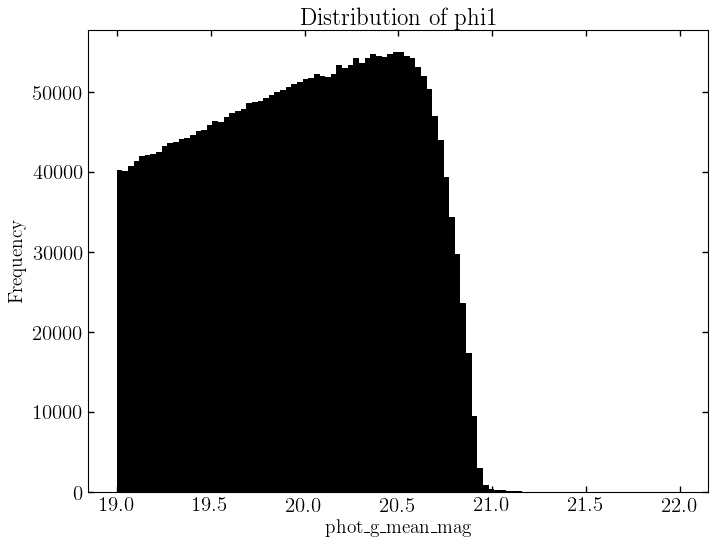

In [89]:
plt.hist(g.phot_g_mean_mag.value, bins=100, range=[19, 22])
plt.xlabel('phot_g_mean_mag')
plt.ylabel('Frequency')
plt.title('Distribution of phi1')
plt.show()

In [42]:
np.sum(data['g0'] > 22)

np.int64(10056)

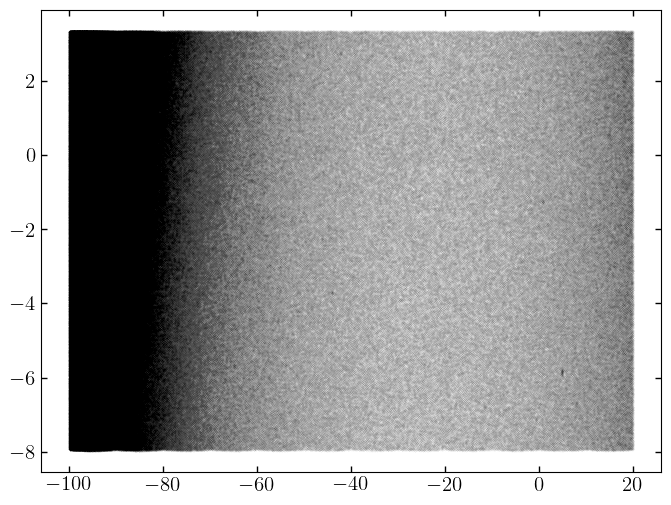

In [3]:
plt.scatter(data['phi1'], data['phi2'], s=0.0001)
plt.show()

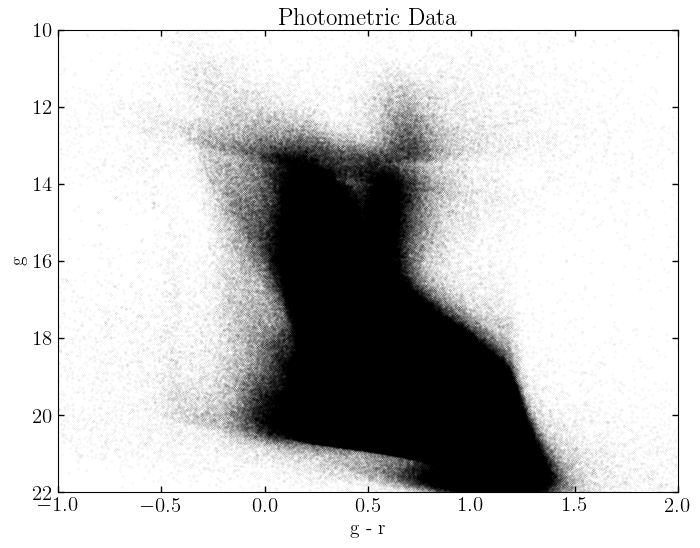

In [4]:
plt.scatter(data['g0'] - data['r0'], data['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(22, 10)
plt.show()

In [5]:
stream_name = 'GD-1'
phi1_lim = (-100, 20)
pawprint = Pawprint.pawprint_from_galstreams(inputs[stream_name]['short_name'],
                                                 inputs[stream_name]['pawprint_id'],
                                                 width=inputs[stream_name]['width'] * u.deg,
                                                 phi1_lim=phi1_lim)

Modifying/extrapolating galstreams track
Modifying/extrapolating galstreams track


In [6]:
 # rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, data, buffer=2)

In [8]:
# Create the CMD cuts
iso_obj_ = Isochrone(data, inputs[stream_name], pawprint=pawprint)
_, _, _, _, pprint = iso_obj_.simpleSln(mass_thresh=0.83)

-40.18182129005669
Fitting for peak pm location
Pre-fitting mean PM values: -13.031, -3.108
Post-fitting (pm1_mean, pm2_mean, pm1_std, pm2_std): [np.float64(-13.274986769345706), np.float64(-3.1794157184284346), np.float64(0.3869370619107417), np.float64(0.5158751767618492)] 

Producing the polygon and mask


/Users/Tavangar/Work/CATS_Workshop/cats/cats/CMD.py:294: RuntimeWarning: invalid value encountered in divide
  signal = signal / signal_counts


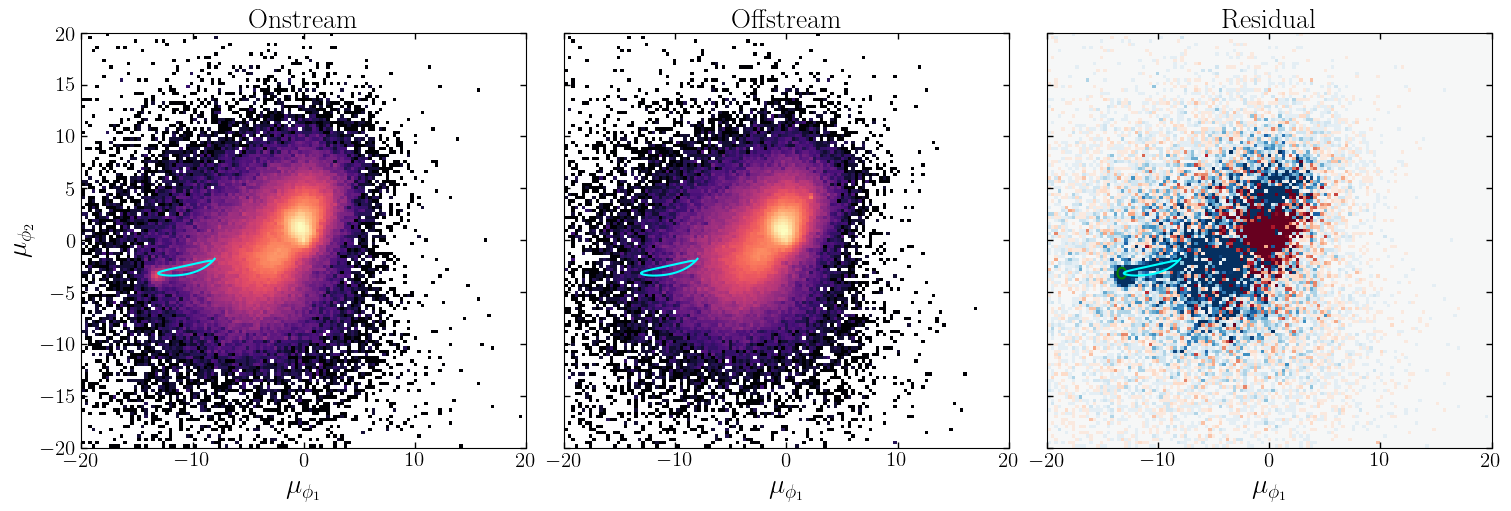

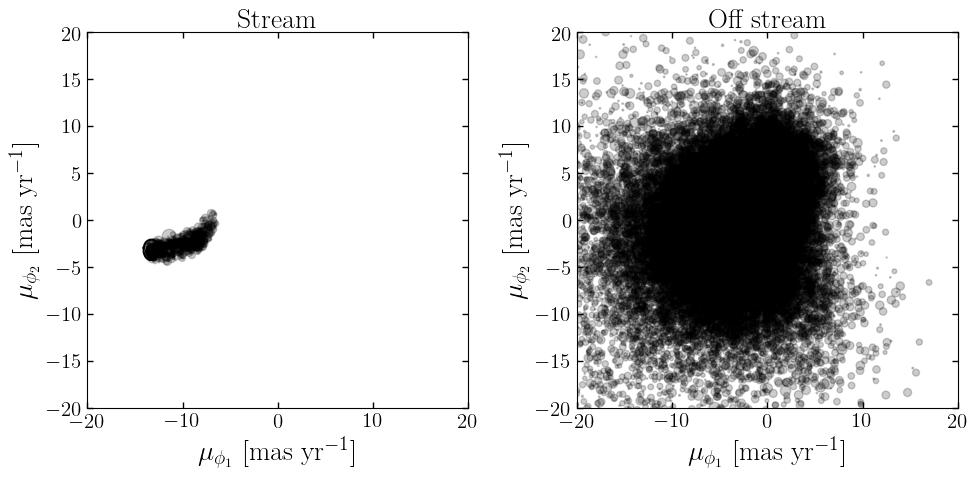

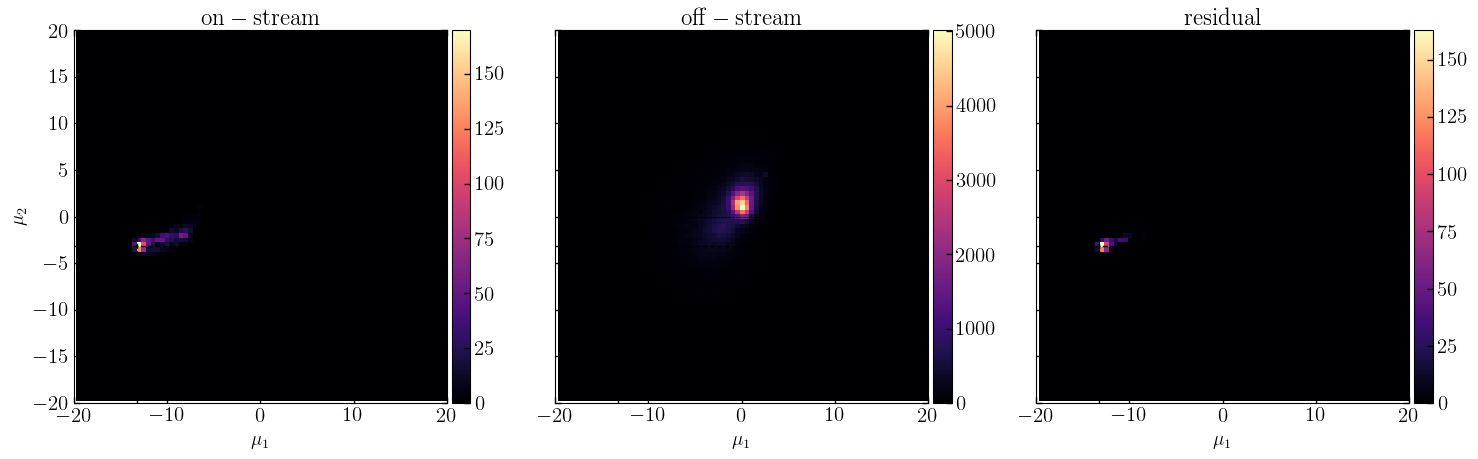

In [10]:
pmsel = ProperMotionSelection(data, inputs[stream_name], pprint,
                                n_dispersion_phi1=3, n_dispersion_phi2=3, cutoff=0.1, plot=True)

iso_obj = Isochrone(data, inputs[stream_name], pawprint=pmsel.pawprint,)
_, iso_mask, _, hb_mask, pprint = iso_obj.simpleSln(mass_thresh=0.83)

In [13]:
##### rough pm cut to start with (this comes only from the galstreams proper motion tracks)
pawprint.pmprint, pm_mask = rough_pm_poly(pawprint, data, buffer=2)

In [62]:
run_data_ = iso_obj.cat[pm_mask]# & (iso_mask | hb_mask)]
bkg_data_ = iso_obj.cat[pm_mask & ~iso_obj.on_skymask]
stream_data_ = iso_obj.cat[pmsel.pm12_mask & (iso_mask | hb_mask) & iso_obj.on_skymask]

In [63]:
print(len(run_data_))
print(len(bkg_data_))

466571
382561


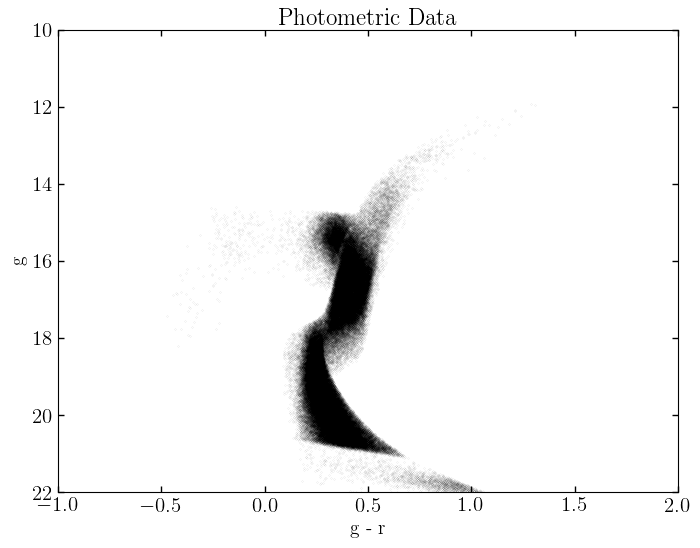

In [19]:
plt.scatter(run_data_['g0'] - run_data_['r0'], run_data_['g0'], s=0.001)
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.xlim(-1, 2); plt.ylim(22, 10)
plt.show()

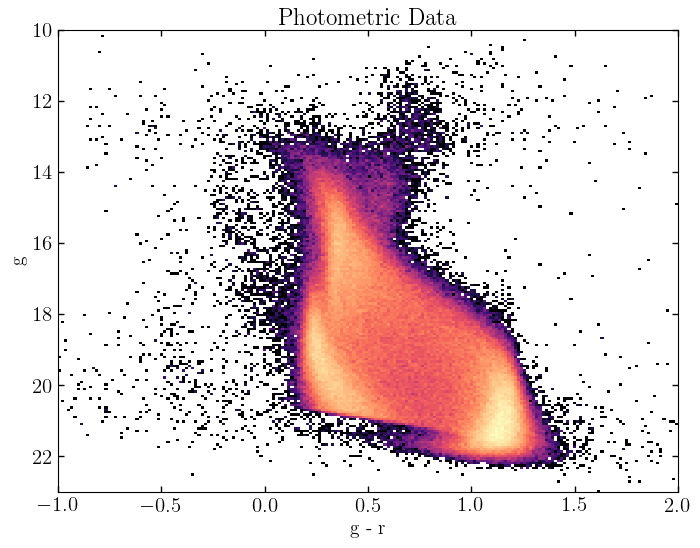

In [67]:
import matplotlib as mpl
plt.hist2d(bkg_data_['g0'] - bkg_data_['r0'], bkg_data_['g0'], bins=200, range=[[-1, 2], [10, 23]], norm=mpl.colors.LogNorm())
plt.xlabel('g - r')
plt.ylabel('g')
plt.title('Photometric Data')
plt.gca().invert_yaxis()
plt.show()

In [64]:
import pickle
post_cats = {'run_data': run_data_,
         'bkg_data': bkg_data_,
         'stream_data': stream_data_,
         'pawprint': pawprint,
         'iso_obj': iso_obj}
with open('../../data/post_cats_data_flow_version.pkl', 'wb') as param_file:
    pickle.dump(post_cats, param_file)

